# Network latency sweep

Runtime as the round-trip latency varies from 10 ms to 200 ms. Bandwidth is fixed at 100 Mbps with a 1 KB request and 2 KB response.

This notebook reads the raw CSVs in this directory, draws the light and dark charts used in the post, and prints the summary table.

In [1]:
SWEEP = "latency"
X = "latency"
XLABEL = "Latency (msec)"
TITLE = "Network latency effect on protocol runtime"
PARAMS = "bandwidth = 100 Mbps  ·  request = 1 KB  ·  response = 2 KB"
LOG_X = False
X_DIVISOR = 1
XTICKS = [10, 25, 50, 75, 100, 150, 200]
XLIM = (5, 215)
YLIM = (0, 17)
LEGEND_LOC = "upper left"

import pandas as pd
import matplotlib.pyplot as plt

COLORS = {
    "dark": {
        "alpha_native": "#8dd3c7", "alpha_browser": "#feffb3",
        "beta_native": "#00d4aa", "beta_browser": "#ffff00",
        "proxy_native": "#ff9f43", "proxy_browser": "#b388ff",
        "footnote": "#999999",
    },
    "light": {
        "alpha_native": "#a6bddb", "alpha_browser": "#f4a6a6",
        "beta_native": "#08519c", "beta_browser": "#cb181d",
        "proxy_native": "#e6550d", "proxy_browser": "#6a51a3",
        "footnote": "#666666",
    },
}

def load_mpc(path):
    df = pd.read_csv(path)
    return df[df["group"].notna() & (df["group"] != "")]

# The previous proxy tip uses an older harness header: the header row starts at
# time_total, while the data rows still contain all 18 columns.
OLD_COLUMNS = [
    "group", "name", "latency", "bandwidth", "upload_size", "download_size",
    "defer_decryption", "proxy", "time_preprocess", "time_online", "time_total",
    "uploaded_preprocess", "downloaded_preprocess", "uploaded_online",
    "downloaded_online", "uploaded_total", "downloaded_total", "heap_max_bytes",
]

def load_proxy(path):
    with open(path) as fh:
        first = fh.readline()
    if first.startswith(",time_total"):
        df = pd.read_csv(path, header=None, skiprows=1, names=OLD_COLUMNS)
    else:
        df = pd.read_csv(path)
    df = df[df["group"].notna() & (df["group"] != "")]
    df["time_total"] = pd.to_numeric(df["time_total"], errors="coerce")
    return df.dropna(subset=["time_total"])

def aggregate(path, loader):
    df = loader(path)
    return df.groupby(X)["time_total"].agg(["mean", "std"]).sort_index() / 1000

# Each series is (legend label, CSV file, loader, color key, line style, width, alpha, z-order).
SERIES = [
    ("alpha.15 MPC native",  f"mpc_{SWEEP}_alpha15_native.csv",  load_mpc, "alpha_native",  ":",  1.4, 0.65, 4),
    ("alpha.15 MPC browser", f"mpc_{SWEEP}_alpha15_browser.csv", load_mpc, "alpha_browser", ":",  1.4, 0.65, 4),
    ("beta.1 MPC native",    f"mpc_{SWEEP}_beta1_native.csv",    load_mpc, "beta_native",   "-",  1.8, 1.00, 5),
    ("beta.1 MPC browser",   f"mpc_{SWEEP}_beta1_browser.csv",   load_mpc, "beta_browser",  "-",  1.8, 1.00, 5),
    ("beta.1 proxy native",  f"proxy_{SWEEP}_beta1_native.csv",  load_proxy, "proxy_native",  "--", 1.6, 1.00, 3),
    ("beta.1 proxy browser", f"proxy_{SWEEP}_beta1_browser.csv", load_proxy, "proxy_browser", "--", 1.6, 1.00, 3),
]

def make_plot(dark, outname):
    theme = "dark" if dark else "light"
    colors = COLORS[theme]
    plt.style.use("dark_background" if dark else "default")
    fig, ax = plt.subplots(figsize=(7.8, 5.2))

    for label, path, loader, color_key, ls, lw, alpha, z in SERIES:
        agg = aggregate(path, loader)
        x = agg.index.to_numpy(dtype=float) / X_DIVISOR
        ax.errorbar(
            x, agg["mean"].to_numpy(), yerr=agg["std"].fillna(0).to_numpy(),
            label=label, color=colors[color_key], linestyle=ls, marker="o",
            linewidth=lw, alpha=alpha, markersize=4, capsize=2, capthick=1,
            elinewidth=0.8, zorder=z, dash_capstyle="round",
        )

    if LOG_X:
        ax.set_xscale("log", base=2)
    ax.set_xticks(XTICKS)
    ax.set_xticklabels([str(int(t)) for t in XTICKS])
    ax.set_xlim(*XLIM)
    ax.set_ylim(*YLIM)
    ax.set_xlabel(XLABEL)
    ax.set_ylabel("Runtime (sec)")
    ax.set_title(TITLE)
    ax.grid(True, linestyle="--", color="gray", alpha=0.3)
    ax.set_axisbelow(True)

    legend = ax.legend(loc=LEGEND_LOC, framealpha=0.9, fontsize=8, ncol=3,
                       columnspacing=1.2, handlelength=2.0)
    for text in legend.get_texts():
        if "alpha.15" in text.get_text():
            text.set_color("#888888")

    fig.text(0.5, -0.01, PARAMS, ha="center", fontsize=8, color=colors["footnote"])
    fig.tight_layout()
    fig.savefig(outname, format="svg", bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.show()

def summary_table():
    means = {label: aggregate(path, loader)["mean"]
             for label, path, loader, *_ in SERIES}
    base = pd.DataFrame(means)
    base.index = base.index / X_DIVISOR
    base.index.name = XLABEL

    previous = {}
    for mode in ["native", "browser"]:
        prev = aggregate(f"proxy_{SWEEP}_previous_{mode}.csv", load_proxy)["mean"]
        prev.index = prev.index / X_DIVISOR
        previous[mode] = prev

    out = pd.DataFrame(index=base.index)
    for mode in ["native", "browser"]:
        out[f"alpha.15 MPC {mode}"] = base[f"alpha.15 MPC {mode}"]
        out[f"beta.1 MPC {mode}"] = base[f"beta.1 MPC {mode}"]
        out[f"MPC {mode} Δ%"] = (base[f"beta.1 MPC {mode}"] / base[f"alpha.15 MPC {mode}"] - 1) * 100
        out[f"previous proxy {mode}"] = previous[mode]
        out[f"beta.1 proxy {mode}"] = base[f"beta.1 proxy {mode}"]
        out[f"proxy {mode} Δ%"] = (base[f"beta.1 proxy {mode}"] / previous[mode] - 1) * 100
    return out.round(2)


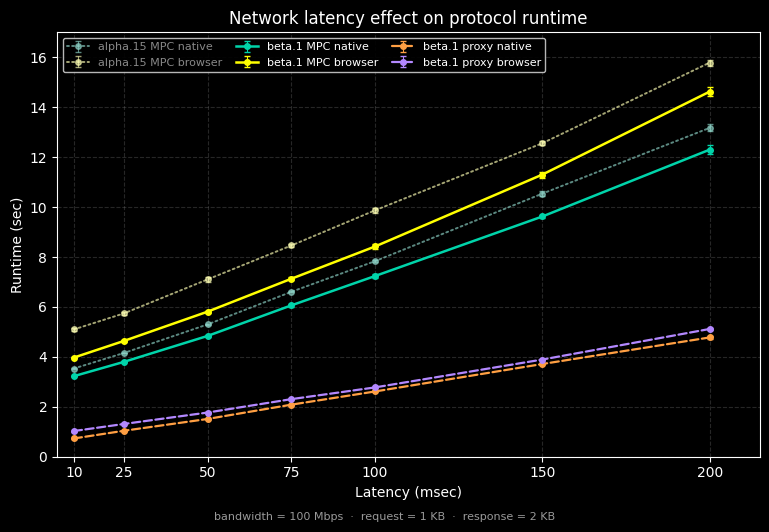

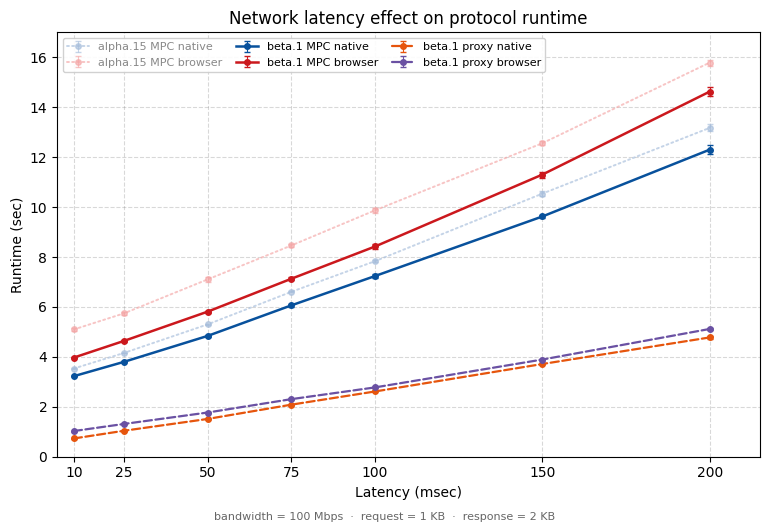

In [2]:
make_plot(True, "latency_dark.svg")
make_plot(False, "latency_light.svg")

In [3]:
table = summary_table()
display(table)

,alpha.15 MPC native,beta.1 MPC native,MPC native Δ%,previous proxy native,beta.1 proxy native,proxy native Δ%,alpha.15 MPC browser,beta.1 MPC browser,MPC browser Δ%,previous proxy browser,beta.1 proxy browser,proxy browser Δ%
Latency (msec),,,,,,,,,,,,
10.0,3.52,3.22,-8.69,0.93,0.72,-21.92,5.09,3.96,-22.14,1.74,1.02,-41.39
25.0,4.15,3.79,-8.60,1.29,1.03,-19.95,5.73,4.63,-19.25,2.07,1.30,-37.12
50.0,5.29,4.83,-8.73,1.86,1.51,-19.23,7.10,5.80,-18.20,2.62,1.76,-32.84
75.0,6.60,6.06,-8.22,2.55,2.08,-18.66,8.45,7.12,-15.77,3.24,2.30,-29.10
100.0,7.83,7.23,-7.61,3.22,2.61,-19.09,9.86,8.41,-14.69,3.80,2.77,-27.20
150.0,10.53,9.62,-8.70,4.57,3.71,-18.88,12.55,11.29,-10.01,5.13,3.89,-24.33
200.0,13.17,12.29,-6.63,5.97,4.77,-20.09,15.78,14.62,-7.37,6.66,5.11,-23.22
